# Phase 0 Baseline Analysis

对比五份 JSON 结果：

| 配置 | 文件 | 视觉 | LLM | 输入 |
|---|---|---|---|---|
| (A) M3D-LaMed × FLAIR | `results_m3dlamed.json` | self vision | Phi-3 4B | 3D npy |
| (A') MedGemma × T1ce | `results_medgemma_t1ce.json` | self vision | Gemma3 4B | 12 slices |
| (A'') MedGemma × FLAIR | `results_medgemma_flair.json` | self vision | Gemma3 4B | 12 slices |
| (D-gt) Claude + KAIST (GT mask) | `results_gt.json` | KAIST | Claude Opus | text features |
| (D-pred) Claude + KAIST (pred mask) | `results_pred.json` | KAIST | Claude Opus | text features |

**两个核心分析**:
1. **4-way system comparison** — 哪个 baseline 在诊断上最准
2. **GT vs Pred equivalence** — KAIST 预测 mask 是否在诊断层面等效于 GT mask (Phase 1 的地基假设)

In [4]:
"""
analyze_qwen3.py

快速分析 Qwen3-14B baseline 的三份结果, 对比 MedGemma 4B 和 Claude.

Usage:
  python analyze_qwen3.py
"""

import json
import re
from pathlib import Path
from collections import Counter

# ===== 改成你的实际文件路径 =====
FILES = {
    "Qwen3-14B + KAIST (GT)":           "D:\\medgemma_brain\\results_qwen3_kaist_gt.json",
    "Qwen3-14B + KAIST (Pred)":         "D:\\medgemma_brain\\results_qwen3_kaist_pred.json",
    "Qwen3-14B + KAIST (Permuted)":   "D:\\medgemma_brain\\results_qwen3_permuted.json",
    # 对比基线
    "MedGemma 4B + KAIST (GT)":         "D:\\medgemma_brain\\results_medgemma_kaist_gt.json",
    "MedGemma 4B + KAIST (Permuted)":   "D:\\medgemma_brain\\results_medgemma_permuted.json",
    "Claude+KAIST (GT)":  "D:\\M3D\\results_claude_gt.json",
    "Claude+KAIST (Pred)":"D:\\M3D\\results_claude_pred.json",
}


def strict_diag(text: str) -> str:
    """严格 parser - 只认明确的诊断声明."""
    if not text:
        return "unknown"
    text_lower = text.lower()

    # JSON 优先
    m = re.search(r'"diagnosis"\s*:\s*"([^"]+)"', text_lower)
    if m:
        return _normalize(m.group(1))

    try:
        data = json.loads(text.strip())
        if "diagnosis" in data:
            return _normalize(str(data["diagnosis"]).lower())
    except Exception:
        pass

    # 文本声明 patterns
    patterns = [
        r"(?:final|primary|most likely|the)\s+diagnosis[:\s]+(?:is\s+)?([a-z\s\-_]+?)(?:[\.\,\n]|$)",
        r"diagnosis[:\s]+([a-z\s\-_]+?)(?:[\.\,\n]|$)",
    ]
    for pat in patterns:
        m = re.search(pat, text_lower)
        if m:
            d = _normalize(m.group(1))
            if d != "unknown":
                return d
    return "unknown"


def _normalize(text: str) -> str:
    text = text.lower().strip().strip(".").strip()
    if re.search(r"\bglioblastoma\b|\bgbm\b|grade\s*(iv|4)\s*glioma|glioblastoma multiforme", text):
        return "glioblastoma"
    if re.search(r"low[\s\-]?grade\s*glioma|grade\s*(ii|2|i|1)\s*glioma|"
                 r"diffuse\s+astrocytoma|oligodendroglioma|pilocytic|\blgg\b", text):
        return "low_grade_glioma"
    if "meningioma" in text:
        return "meningioma"
    if re.search(r"metasta(sis|tic|ses)", text):
        return "metastasis"
    if "lymphoma" in text:
        return "lymphoma"
    if "abscess" in text:
        return "abscess"
    if re.search(r"\btumor\b|\bmass\b|\blesion\b|neoplasm", text):
        return "other"
    return "unknown"


def analyze_file(name: str, path: str):
    p = Path(path)
    if not p.exists():
        return None

    data = json.loads(p.read_text(encoding="utf-8"))
    cases = [c for c in data.values() if isinstance(c, dict) and "error" not in c]
    n = len(cases)
    if n == 0:
        return None

    # 用严格 parser 抽诊断
    diagnoses = []
    confidences = []
    inference_times = []
    for c in cases:
        raw = c.get("raw_output", "")
        diag = strict_diag(raw)
        diagnoses.append(diag)

        parsed = c.get("parsed", {})
        conf = parsed.get("confidence", 0)
        if isinstance(conf, (int, float)):
            confidences.append(float(conf))
        else:
            confidences.append(0)

        t = c.get("inference_time_s", 0)
        if isinstance(t, (int, float)):
            inference_times.append(float(t))

    correct = sum(1 for d in diagnoses if d == "glioblastoma")
    diag_dist = Counter(diagnoses)

    avg_conf = sum(confidences) / max(len(confidences), 1)
    avg_time = sum(inference_times) / max(len(inference_times), 1)

    return {
        "name": name,
        "n": n,
        "correct": correct,
        "accuracy": 100 * correct / n,
        "diag_dist": diag_dist,
        "avg_confidence": avg_conf,
        "avg_time_s": avg_time,
    }


def main():
    print("Qwen3-14B Phase 0 Analysis (with comparison baselines)")

    results = {}
    for name, path in FILES.items():
        r = analyze_file(name, path)
        if r is not None:
            results[name] = r
        else:
            print(f"⚠️  {name}: file not found ({path})")

    # Table
    print(f"\n{'System':<40s} {'Acc':>7s} {'Conf':>7s} {'Time/c':>8s}  Distribution")
    print("-" * 75)
    for r in results.values():
        dist_str = ", ".join(f"{d}:{c}" for d, c in r['diag_dist'].most_common(3))
        print(f"{r['name']:<40s} {r['accuracy']:>5.0f}% {r['avg_confidence']:>6.2f} "
              f"{r['avg_time_s']:>7.1f}s  {dist_str}")

    # Key comparisons
    print("KEY COMPARISONS")

    # Qwen3 GT vs Permuted (核心: 是不是真在推理)
    qwen_gt = results.get("Qwen3-14B + KAIST (GT)")
    qwen_perm = results.get("Qwen3-14B + KAIST (Permuted)")
    if qwen_gt and qwen_perm:
        delta = qwen_perm["accuracy"] - qwen_gt["accuracy"]
        print(f"\n[Qwen3 推理稳定性] Permutation 控制实验")
        print(f"  原版 (glioblastoma 第一): {qwen_gt['accuracy']:.0f}%")
        print(f"  对照 (meningioma 第一):   {qwen_perm['accuracy']:.0f}%")
        print(f"  Delta: {delta:+.0f} pp")
        if abs(delta) <= 10:
            print(f"  ✅ Qwen3-14B 在做真正的诊断推理 (permutation invariant)")
        elif abs(delta) <= 30:
            print(f"  ⚠️  Qwen3-14B 部分依赖选项顺序, 但仍有真实推理能力")
        else:
            print(f"  ❌ Qwen3-14B 主要在选第一个选项, 14B 也不够")

    # Scaling: MedGemma 4B vs Qwen3 14B vs Claude (permutation 后真实数字)
    medgemma_perm = results.get("MedGemma 4B + KAIST (Permuted)")
    claude_gt = results.get("Claude + KAIST (GT)")
    if qwen_perm and medgemma_perm and claude_gt:
        print(f"\n[LLM Scaling on Specialist+LLM 架构] 真实诊断准确率")
        print(f"  MedGemma 4B    + KAIST (permuted): {medgemma_perm['accuracy']:.0f}%")
        print(f"  Qwen3 14B      + KAIST (permuted): {qwen_perm['accuracy']:.0f}%")
        print(f"  Claude (frontier) + KAIST (GT):    {claude_gt['accuracy']:.0f}%")

        delta_4_to_14 = qwen_perm['accuracy'] - medgemma_perm['accuracy']
        delta_14_to_claude = claude_gt['accuracy'] - qwen_perm['accuracy']
        print(f"\n  Delta 4B → 14B: {delta_4_to_14:+.0f} pp")
        print(f"  Delta 14B → Claude: {delta_14_to_claude:+.0f} pp")

        if qwen_perm["accuracy"] >= 70:
            print(f"\n  ✅ 14B 已经具备真实诊断推理能力 (≥70%)")
            print(f"     proposal 的 LoRA 训练路径有强支撑")
        elif qwen_perm["accuracy"] >= 50:
            print(f"\n  ⚠️  14B 处于过渡期 (50-70%)")
            print(f"     LoRA + RL 可能能进一步提升, 但需要 process reward")
        else:
            print(f"\n  ❌ 14B 也不够 (<50%)")
            print(f"     proposal 需要重新设计 — 用 frontier API 而非微调")

    # GT vs Pred (Qwen3)
    qwen_pred = results.get("Qwen3-14B + KAIST (Pred)")
    if qwen_gt and qwen_pred:
        agreement = 100 * sum(1 for d1, d2 in zip(
            [strict_diag(c.get("raw_output", "")) for c in
             json.loads(Path(FILES["Qwen3-14B + KAIST (GT)"]).read_text(encoding="utf-8")).values()
             if isinstance(c, dict)],
            [strict_diag(c.get("raw_output", "")) for c in
             json.loads(Path(FILES["Qwen3-14B + KAIST (Pred)"]).read_text(encoding="utf-8")).values()
             if isinstance(c, dict)]
        ) if d1 == d2) / qwen_gt["n"]
        print(f"\n[Qwen3: GT mask vs Pred mask] Diagnostic agreement: {agreement:.0f}%")


if __name__ == "__main__":
    main()

Qwen3-14B Phase 0 Analysis (with comparison baselines)

System                                       Acc    Conf   Time/c  Distribution
---------------------------------------------------------------------------
Qwen3-14B + KAIST (GT)                      98%   0.84    45.9s  glioblastoma:49, unknown:1
Qwen3-14B + KAIST (Pred)                    96%   0.84    53.7s  glioblastoma:48, unknown:2
Qwen3-14B + KAIST (Permuted)                96%   0.86    23.9s  glioblastoma:48, unknown:2
MedGemma 4B + KAIST (GT)                   100%   0.00    27.5s  glioblastoma:50
MedGemma 4B + KAIST (Permuted)              26%   0.00    32.6s  unknown:23, glioblastoma:13, meningioma:10
Claude+KAIST (GT)                           94%   0.70     0.0s  glioblastoma:47, unknown:2, metastasis:1
Claude+KAIST (Pred)                         92%   0.70     0.0s  glioblastoma:46, unknown:3, metastasis:1
KEY COMPARISONS

[Qwen3 推理稳定性] Permutation 控制实验
  原版 (glioblastoma 第一): 98%
  对照 (meningioma 第一):   96%
  Delta

In [1]:
# Cell 1: 导入和配置
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 10

RESULTS = {
    "M3D (FLAIR)":        "D:\\M3D\\results_m3dlamed_flair.json",
    "M3D (T1ce)":         "D:\\M3D\\results_m3dlamed_t1ce.json",
    "MedGemma (T1ce)":    "D:\\medgemma_brain\\results_medgemma_t1ce.json",
    "MedGemma (FLAIR)":   "D:\\medgemma_brain\\results_medgemma_flair.json",
    "Claude+KAIST (GT)":  "D:\\M3D\\results_claude_gt.json",
    "Claude+KAIST (Pred)":"D:\\M3D\\results_claude_pred.json",
    "Claude+KAIST+img (GT)":  "D:\\M3D\\results_d2_gt.json",
    "Claude+KAIST+img (Pred)": "D:\\M3D\\results_d2_pred.json",
    "MedGemma+KAIST (GT)":  "D:\\medgemma_brain\\results_medgemma_kaist_gt.json",
    "MedGemma+KAIST (Pred)":  "D:\\medgemma_brain\\results_medgemma_kaist_pred.json",
}

# BraTS 2021 全部是 GBM — 这是我们的 ground truth
GT_DIAGNOSIS = "glioblastoma"
GT_GRADE = "high"

# 配色 (按 system 类型)
COLORS = {
    "M3D (FLAIR)":         "#E15759",   # 红 - end-to-end MLLM
    "MedGemma (T1ce)":     "#F28E2B",   # 橙 - end-to-end MLLM
    "M3D (T1ce)":          "#C03C3E",   # 深红
    "MedGemma (FLAIR)":    "#FFA76A",   # 浅橙
    "MedGemma+KAIST (GT)":     "#2E8B57",
    "MedGemma+KAIST (Pred)":   "#7CC27A",
    "Claude+KAIST (GT)":       "#4E79A7",   # 蓝 - specialist+LLM
    "Claude+KAIST+img (GT)":   "#6A0DAD",    # 紫 — 多模态
    "Claude+KAIST (Pred)": "#86B4D9",   # 浅蓝
}


In [2]:
def extract_record(system: str, case_id: str, data: dict) -> dict:
    """统一不同 baseline 的输出 schema."""
    rec = {
        "system": system,
        "case_id": case_id,
        "diagnosis":   "unknown",
        "laterality":  "unknown",
        "lobe":        "unknown",
        "grade":       "unknown",
        "enhancement": "unknown",
        "raw_text":    "",
    }

    if "parsed" in data:
        p = data["parsed"]
        rec.update({
            "diagnosis":   p.get("diagnosis", "unknown"),
            "laterality":  p.get("laterality", "unknown"),
            "lobe":        p.get("lobe", "unknown"),
            "grade":       p.get("grade", "unknown"),
            "enhancement": p.get("enhancement", "unknown"),
            "raw_text":    data.get("raw_output", ""),
        })
    else:
        rec.update({
            "diagnosis":   data.get("diagnosis", "unknown"),
            "laterality":  data.get("laterality", "unknown"),
            "lobe":        data.get("lobe", "unknown"),
            "grade":       data.get("grade", "unknown"),
            "enhancement": data.get("enhancement", "unknown"),
            "raw_text":    data.get("raw_output",
                            data.get("raw_description", "") + " " +
                            data.get("raw_diagnosis", "")).strip(),
        })
    for k in ["diagnosis", "laterality", "lobe", "grade", "enhancement"]:
        if isinstance(rec[k], str):
            rec[k] = rec[k].lower().strip() if k != "laterality" else rec[k].upper().strip()
    return rec

rows = []
for system, path in RESULTS.items():
    p = Path(path)
    if not p.exists():
        print(f"{system}: {path} 不存在, 跳过")
        continue
    data = json.loads(p.read_text(encoding="utf-8"))
    n_loaded = 0
    for case_id, case_data in data.items():
        if not isinstance(case_data, dict) or "error" in case_data:
            continue
        rows.append(extract_record(system, case_id, case_data))
        n_loaded += 1
    print(f"{system}: {n_loaded} cases loaded")

df = pd.DataFrame(rows)
print(f"\nTotal records: {len(df)}")
df

M3D (FLAIR): 50 cases loaded
M3D (T1ce): 50 cases loaded
MedGemma (T1ce): 50 cases loaded
MedGemma (FLAIR): 50 cases loaded
Claude+KAIST (GT): 50 cases loaded
Claude+KAIST (Pred): 50 cases loaded
Claude+KAIST+img (GT): 50 cases loaded
Claude+KAIST+img (Pred): 50 cases loaded
MedGemma+KAIST (GT): 50 cases loaded
MedGemma+KAIST (Pred): 50 cases loaded

Total records: 500


,system,case_id,diagnosis,laterality,lobe,grade,enhancement,raw_text
0,M3D (FLAIR),BraTS2021_00000,other,LEFT,unknown,unknown,unknown,There is a large lytic lesion occupying the en...
1,M3D (FLAIR),BraTS2021_00002,other,LEFT,unknown,unknown,unknown,There is an expansile lytic lesion of the left...
2,M3D (FLAIR),BraTS2021_00003,other,UNKNOWN,unknown,unknown,unknown,There is a large heterogeneous lesion in theer...
3,M3D (FLAIR),BraTS2021_00005,other,UNKNOWN,unknown,unknown,unknown,There is an irregular and asymmetric increase ...
4,M3D (FLAIR),BraTS2021_00006,other,UNKNOWN,unknown,unknown,ring,There is a large lobulated soft tissue mass is...
...,...,...,...,...,...,...,...,...
495,MedGemma+KAIST (Pred),BraTS2021_00066,glioblastoma,RIGHT,frontal,high,ring,"{""diagnosis"": ""glioblastoma"", ""confidence"": 0...."
496,MedGemma+KAIST (Pred),BraTS2021_00068,glioblastoma,RIGHT,deep,high,heterogeneous,"{""diagnosis"": ""glioblastoma"", ""confidence"": 0...."
497,MedGemma+KAIST (Pred),BraTS2021_00070,glioblastoma,LEFT,frontal,high,heterogeneous,"{""diagnosis"": ""glioblastoma"", ""confidence"": 0...."
498,MedGemma+KAIST (Pred),BraTS2021_00071,glioblastoma,RIGHT,occipital,high,ring,"{""diagnosis"": ""glioblastoma"", ""confidence"": 0...."



诊断 & 分级准确率 (%):
                         correct_diagnosis  correct_grade  n_cases
system                                                            
M3D (FLAIR)                            0.0            0.0       50
M3D (T1ce)                             0.0            2.0       50
MedGemma (T1ce)                       52.0           52.0       50
MedGemma (FLAIR)                      22.0           22.0       50
Claude+KAIST (GT)                     94.0           96.0       50
Claude+KAIST (Pred)                   92.0           94.0       50
Claude+KAIST+img (GT)                 94.0           98.0       50
Claude+KAIST+img (Pred)               94.0           98.0       50
MedGemma+KAIST (GT)                  100.0          100.0       50
MedGemma+KAIST (Pred)                100.0          100.0       50


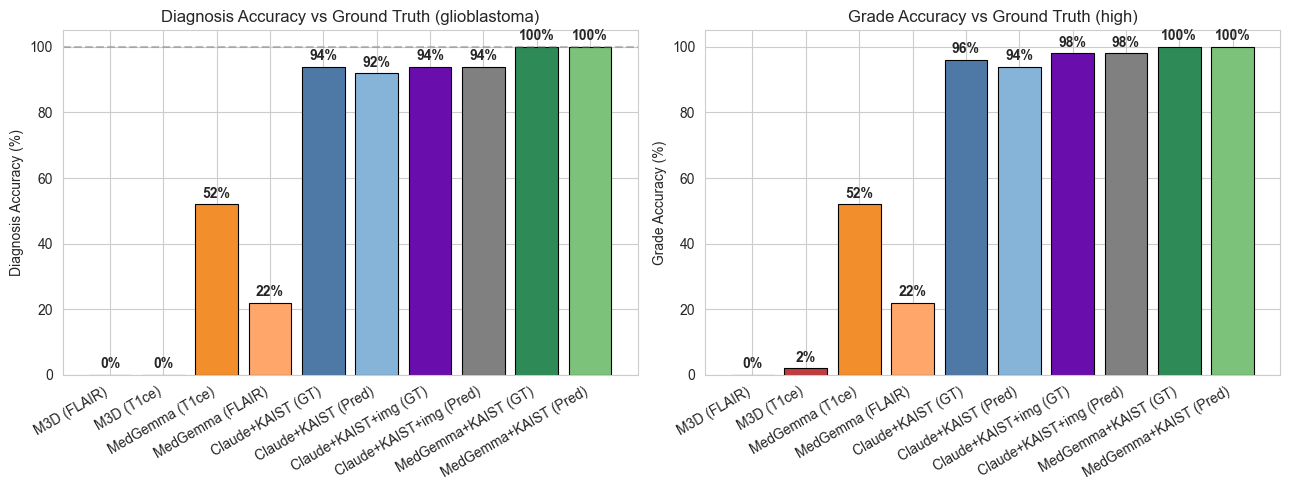

In [3]:

df["correct_diagnosis"] = df["diagnosis"] == GT_DIAGNOSIS
df["correct_grade"]     = df["grade"] == GT_GRADE

system_acc = df.groupby("system").agg({
    "correct_diagnosis": "mean",
    "correct_grade":     "mean",
    "case_id":           "count",
}).rename(columns={"case_id": "n_cases"})

# 保持指定顺序
system_acc = system_acc.reindex([s for s in RESULTS if s in system_acc.index])
system_acc["correct_diagnosis"] = (system_acc["correct_diagnosis"] * 100).round(1)
system_acc["correct_grade"]     = (system_acc["correct_grade"] * 100).round(1)
print("\n诊断 & 分级准确率 (%):")
print(system_acc)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

systems = list(system_acc.index)
colors = [COLORS.get(s, "gray") for s in systems]
ax = axes[0]
bars = ax.bar(range(len(systems)), system_acc["correct_diagnosis"],
              color=colors, edgecolor="black", linewidth=0.8)
ax.set_xticks(range(len(systems)))
ax.set_xticklabels(systems, rotation=30, ha="right")
ax.set_ylabel("Diagnosis Accuracy (%)")
ax.set_title(f"Diagnosis Accuracy vs Ground Truth ({GT_DIAGNOSIS})")
ax.set_ylim(0, 105)
ax.axhline(100, ls="--", c="gray", alpha=0.5, label="Oracle")
for i, v in enumerate(system_acc["correct_diagnosis"]):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontweight="bold")

ax = axes[1]
bars = ax.bar(range(len(systems)), system_acc["correct_grade"],
              color=colors, edgecolor="black", linewidth=0.8)
ax.set_xticks(range(len(systems)))
ax.set_xticklabels(systems, rotation=30, ha="right")
ax.set_ylabel("Grade Accuracy (%)")
ax.set_title(f"Grade Accuracy vs Ground Truth ({GT_GRADE})")
ax.set_ylim(0, 105)
for i, v in enumerate(system_acc["correct_grade"]):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("fig1_diagnosis_accuracy.png", bbox_inches="tight")
plt.show()

识别率 (% of cases where field is not 'unknown'):
                         lat_known  lobe_known  enh_known
system                                                   
M3D (FLAIR)                   52.0        18.0       38.0
M3D (T1ce)                    72.0        10.0       40.0
MedGemma (T1ce)               94.0        94.0       98.0
MedGemma (FLAIR)             100.0        96.0       32.0
Claude+KAIST (GT)            100.0       100.0      100.0
Claude+KAIST (Pred)          100.0       100.0      100.0
Claude+KAIST+img (GT)        100.0       100.0      100.0
Claude+KAIST+img (Pred)      100.0       100.0      100.0
MedGemma+KAIST (GT)          100.0       100.0      100.0
MedGemma+KAIST (Pred)        100.0       100.0      100.0


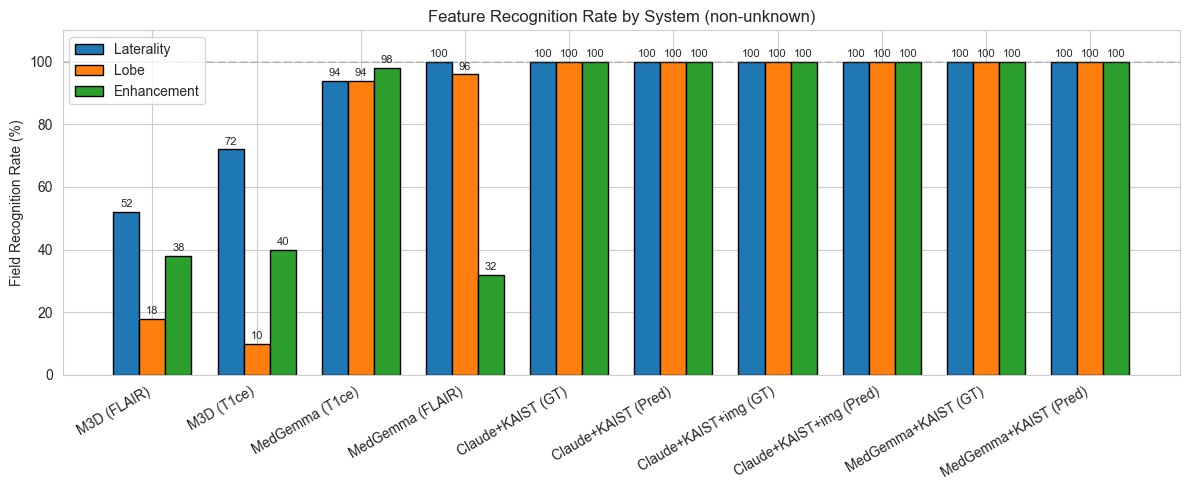

In [4]:
known_stats = df.groupby("system").agg(
    lat_known =("laterality",  lambda x: (x != "UNKNOWN").mean()),
    lobe_known=("lobe",        lambda x: (x != "unknown").mean()),
    enh_known =("enhancement", lambda x: (x != "unknown").mean()),
)
known_stats = (known_stats * 100).round(1).reindex([s for s in RESULTS if s in known_stats.index])
print("识别率 (% of cases where field is not 'unknown'):")
print(known_stats)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(known_stats))
width = 0.25

ax.bar(x - width, known_stats["lat_known"],  width, label="Laterality",   edgecolor="black")
ax.bar(x,         known_stats["lobe_known"], width, label="Lobe",          edgecolor="black")
ax.bar(x + width, known_stats["enh_known"],  width, label="Enhancement", edgecolor="black")

ax.set_xticks(x)
ax.set_xticklabels(known_stats.index, rotation=30, ha="right")
ax.set_ylabel("Field Recognition Rate (%)")
ax.set_title("Feature Recognition Rate by System (non-unknown)")
ax.set_ylim(0, 110)
ax.legend(loc="upper left")
ax.axhline(100, ls="--", c="gray", alpha=0.3)

for i, row in enumerate(known_stats.itertuples()):
    for offset, val in zip([-width, 0, width], [row.lat_known, row.lobe_known, row.enh_known]):
        ax.text(i + offset, val + 1.5, f"{val:.0f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("fig2_field_recognition.png", bbox_inches="tight")
plt.show()

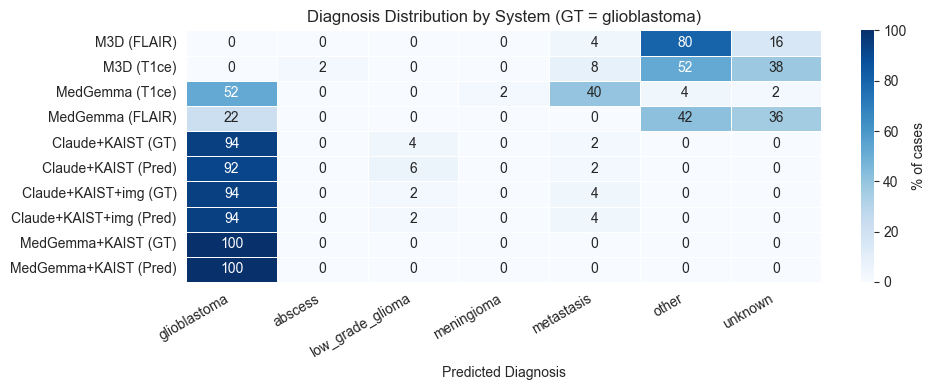


诊断分布 (%):
diagnosis                glioblastoma  abscess  low_grade_glioma  meningioma  \
system                                                                         
M3D (FLAIR)                       0.0      0.0               0.0         0.0   
M3D (T1ce)                        0.0      2.0               0.0         0.0   
MedGemma (T1ce)                  52.0      0.0               0.0         2.0   
MedGemma (FLAIR)                 22.0      0.0               0.0         0.0   
Claude+KAIST (GT)                94.0      0.0               4.0         0.0   
Claude+KAIST (Pred)              92.0      0.0               6.0         0.0   
Claude+KAIST+img (GT)            94.0      0.0               2.0         0.0   
Claude+KAIST+img (Pred)          94.0      0.0               2.0         0.0   
MedGemma+KAIST (GT)             100.0      0.0               0.0         0.0   
MedGemma+KAIST (Pred)           100.0      0.0               0.0         0.0   

diagnosis                met

In [5]:
diag_dist = df.groupby(["system", "diagnosis"]).size().unstack(fill_value=0)
diag_pct = diag_dist.div(diag_dist.sum(axis=1), axis=0) * 100
# 排序: GT 诊断放第一列
cols = [GT_DIAGNOSIS] + [c for c in diag_pct.columns if c != GT_DIAGNOSIS]
diag_pct = diag_pct.reindex(columns=[c for c in cols if c in diag_pct.columns])
diag_pct = diag_pct.reindex([s for s in RESULTS if s in diag_pct.index])

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(diag_pct, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% of cases"}, vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title(f"Diagnosis Distribution by System (GT = {GT_DIAGNOSIS})")
ax.set_xlabel("Predicted Diagnosis")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("fig3_diagnosis_heatmap.png", bbox_inches="tight")
plt.show()

print("\n诊断分布 (%):")
print(diag_pct.round(0))

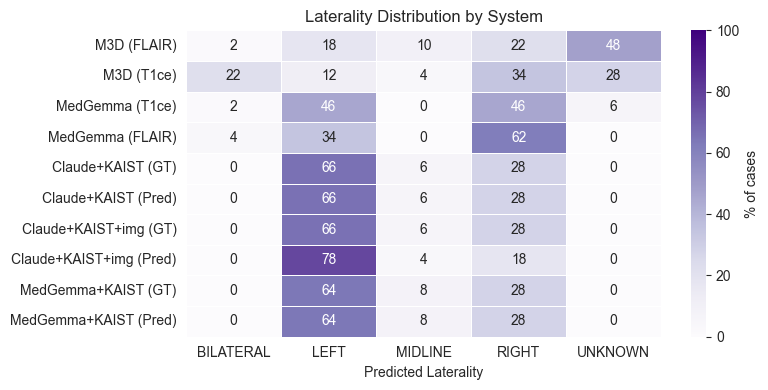


Laterality 分布 (%):
laterality               BILATERAL  LEFT  MIDLINE  RIGHT  UNKNOWN
system                                                           
M3D (FLAIR)                    2.0  18.0     10.0   22.0     48.0
M3D (T1ce)                    22.0  12.0      4.0   34.0     28.0
MedGemma (T1ce)                2.0  46.0      0.0   46.0      6.0
MedGemma (FLAIR)               4.0  34.0      0.0   62.0      0.0
Claude+KAIST (GT)              0.0  66.0      6.0   28.0      0.0
Claude+KAIST (Pred)            0.0  66.0      6.0   28.0      0.0
Claude+KAIST+img (GT)          0.0  66.0      6.0   28.0      0.0
Claude+KAIST+img (Pred)        0.0  78.0      4.0   18.0      0.0
MedGemma+KAIST (GT)            0.0  64.0      8.0   28.0      0.0
MedGemma+KAIST (Pred)          0.0  64.0      8.0   28.0      0.0


In [6]:
lat_dist = df.groupby(["system", "laterality"]).size().unstack(fill_value=0)
lat_pct = lat_dist.div(lat_dist.sum(axis=1), axis=0) * 100
lat_pct = lat_pct.reindex([s for s in RESULTS if s in lat_pct.index])

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(lat_pct, annot=True, fmt=".0f", cmap="Purples",
            cbar_kws={"label": "% of cases"}, vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Laterality Distribution by System")
ax.set_xlabel("Predicted Laterality")
ax.set_ylabel("")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("fig4_laterality_heatmap.png", bbox_inches="tight")
plt.show()
print("\nLaterality 分布 (%):")
print(lat_pct.round(0))

## GT mask vs Pred mask 等效性分析 (Phase 0 的地基测试)

核心问题: 用 KAIST 的 Dice 0.95 预测 mask 提取特征, 得到的诊断是否和用 GT mask 提取特征等效?

- **Agreement ≥ 85%**: Phase 1 可以假设 segmentation 是 reliable observation, 直接推进
- **Agreement 60-85%**: 分析 disagreement cases, 看是否和 Dice 偏低相关
- **Agreement < 60%**: Phase 1 需要加 mask uncertainty estimation (MC dropout / TTA)

In [7]:
# Cell 7: GT vs Pred 配对分析

df_gt   = df[df.system == "Claude+KAIST (GT)"].set_index("case_id")
df_pred = df[df.system == "Claude+KAIST (Pred)"].set_index("case_id")

common = sorted(set(df_gt.index) & set(df_pred.index))
print(f"共同 case 数: {len(common)}")

pair = pd.DataFrame({
    "gt_diagnosis":   df_gt.loc[common, "diagnosis"].values,
    "pred_diagnosis": df_pred.loc[common, "diagnosis"].values,
    "gt_laterality":  df_gt.loc[common, "laterality"].values,
    "pred_laterality":df_pred.loc[common, "laterality"].values,
    "gt_lobe":        df_gt.loc[common, "lobe"].values,
    "pred_lobe":      df_pred.loc[common, "lobe"].values,
    "gt_grade":       df_gt.loc[common, "grade"].values,
    "pred_grade":     df_pred.loc[common, "grade"].values,
    "gt_enh":         df_gt.loc[common, "enhancement"].values,
    "pred_enh":       df_pred.loc[common, "enhancement"].values,
}, index=common)

agreements = {
    "Diagnosis":    (pair.gt_diagnosis  == pair.pred_diagnosis).mean() * 100,
    "Laterality":   (pair.gt_laterality == pair.pred_laterality).mean() * 100,
    "Lobe":         (pair.gt_lobe       == pair.pred_lobe).mean() * 100,
    "Grade":        (pair.gt_grade      == pair.pred_grade).mean() * 100,
    "Enhancement":  (pair.gt_enh        == pair.pred_enh).mean() * 100,
}
print("\nGT vs Pred Agreement (%):")
for k, v in agreements.items():
    print(f"  {k:15s}: {v:5.1f}%")

共同 case 数: 50

GT vs Pred Agreement (%):
  Diagnosis      :  98.0%
  Laterality     :  96.0%
  Lobe           : 100.0%
  Grade          :  98.0%
  Enhancement    :  92.0%


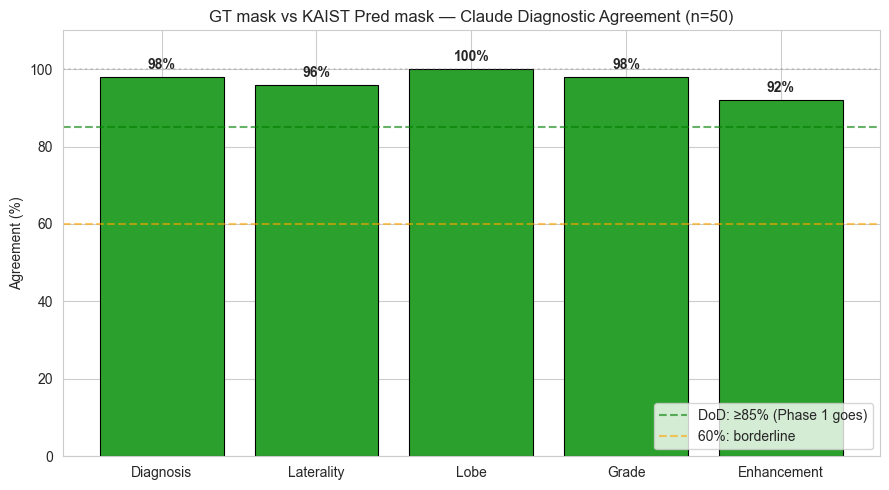

Diagnosis agreement = 98.0% ≥ 85%
   Phase 1 可以假设 segmentation 是 reliable evidence, 直接推进.


In [8]:
# Cell 8: GT vs Pred 条形图 + DoD 阈值线

fig, ax = plt.subplots(figsize=(9, 5))
fields = list(agreements.keys())
values = list(agreements.values())

# 根据 agreement 水平着色
bar_colors = [
    "#2ca02c" if v >= 85 else "#ff7f0e" if v >= 60 else "#d62728"
    for v in values
]
bars = ax.bar(fields, values, color=bar_colors, edgecolor="black", linewidth=0.8)

# DoD 阈值
ax.axhline(85, ls="--", c="green", alpha=0.6, label="DoD: ≥85% (Phase 1 goes)")
ax.axhline(60, ls="--", c="orange", alpha=0.6, label="60%: borderline")
ax.axhline(100, ls=":", c="gray", alpha=0.3)

ax.set_ylabel("Agreement (%)")
ax.set_title(f"GT mask vs KAIST Pred mask — Claude Diagnostic Agreement (n={len(common)})")
ax.set_ylim(0, 110)
ax.legend(loc="lower right")

for i, v in enumerate(values):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("fig5_gt_vs_pred_agreement.png", bbox_inches="tight")
plt.show()

# Verdict
diag_agreement = agreements["Diagnosis"]
if diag_agreement >= 85:
    print(f"Diagnosis agreement = {diag_agreement:.1f}% ≥ 85%")
    print("   Phase 1 可以假设 segmentation 是 reliable evidence, 直接推进.")
elif diag_agreement >= 60:
    print(f"Diagnosis agreement = {diag_agreement:.1f}% (60-85%)")
    print("   分析下方 disagreement cases, 检查是否与 Dice 偏低相关.")
else:
    print(f"Diagnosis agreement = {diag_agreement:.1f}% < 60%")
    print("   Phase 1 需要加 mask uncertainty estimation 作为必需组件.")

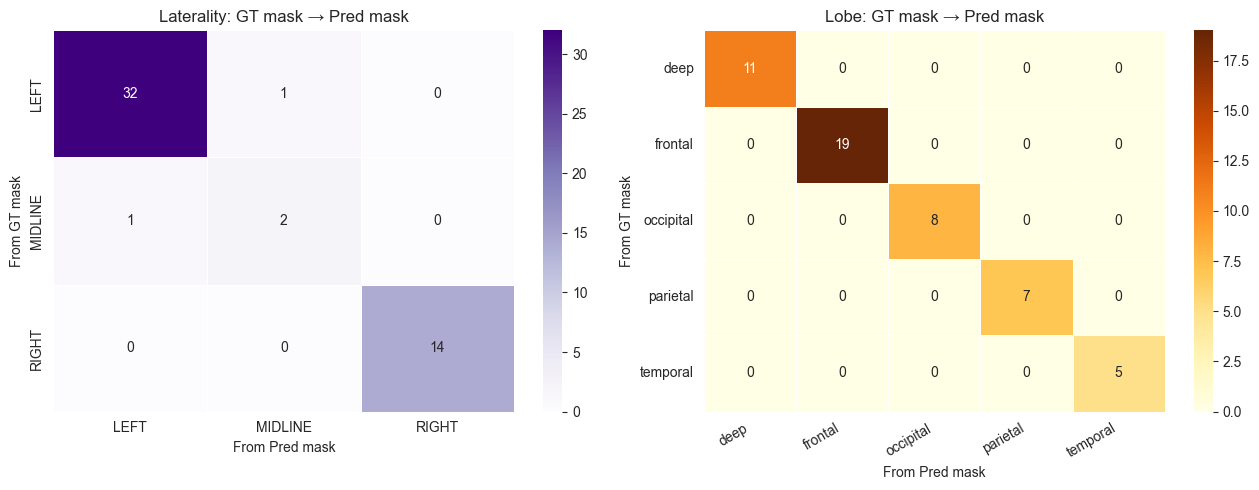

In [9]:
# Cell 9: Laterality/Lobe disagreement confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Laterality confusion
lat_cm = pd.crosstab(pair.gt_laterality, pair.pred_laterality)
sns.heatmap(lat_cm, annot=True, fmt="d", cmap="Purples",
            linewidths=0.5, linecolor="white", ax=axes[0])
axes[0].set_title("Laterality: GT mask → Pred mask")
axes[0].set_xlabel("From Pred mask")
axes[0].set_ylabel("From GT mask")

# Lobe confusion
lobe_cm = pd.crosstab(pair.gt_lobe, pair.pred_lobe)
sns.heatmap(lobe_cm, annot=True, fmt="d", cmap="YlOrBr",
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_title("Lobe: GT mask → Pred mask")
axes[1].set_xlabel("From Pred mask")
axes[1].set_ylabel("From GT mask")
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")
plt.setp(axes[1].get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig("fig6_confusion_matrices.png", bbox_inches="tight")
plt.show()

In [10]:
# Cell 10: 导出 disagreement cases 供人工审查

disagree = pair[pair.gt_diagnosis != pair.pred_diagnosis].copy()
print(f"诊断 disagreement 的 case 数: {len(disagree)}")
if len(disagree) > 0:
    print("\n前 10 个 case:")
    print(disagree[["gt_diagnosis", "pred_diagnosis",
                    "gt_laterality", "pred_laterality",
                    "gt_lobe", "pred_lobe"]].head(10))
    disagree.to_csv("disagreement_cases.csv")
    print(f"\n已保存到 disagreement_cases.csv (共 {len(disagree)} cases)")
else:
    print("全部一致! 没有 disagreement case.")

诊断 disagreement 的 case 数: 1

前 10 个 case:
                 gt_diagnosis    pred_diagnosis gt_laterality pred_laterality  \
BraTS2021_00017  glioblastoma  low_grade_glioma          LEFT            LEFT   

                gt_lobe pred_lobe  
BraTS2021_00017    deep      deep  

已保存到 disagreement_cases.csv (共 1 cases)


## Phase 0 Findings 总结

根据以上分析回答几个关键问题:

1. **纯 end-to-end MLLM 在 BraTS 上表现如何?** (看 M3D-LaMed / MedGemma 的 diagnosis accuracy)
2. **Specialist+LLM (Claude+KAIST) 是否明显更强?** (看 Claude+KAIST 和 MLLM 的差距)
3. **Dice 0.95 的预测 mask 能替代 GT 吗?** (看 Diagnosis agreement ≥ 85% 是否成立)

这些数字直接进入 Phase 0 findings report (`phase0_findings.md` 的 Finding 1/2/3).

In [11]:
# Cell 11: Phase 0 findings 自动摘要

print("PHASE 0 FINDINGS — AUTO SUMMARY")

def acc(s, field="correct_diagnosis"):
    if s in system_acc.index:
        return system_acc.loc[s, field]
    return None

# Finding 1: End-to-end MLLM
print("\n### Finding 1: End-to-end MLLM baseline\n")
for s in ["M3D (FLAIR)", "M3D (T1ce)", "MedGemma (T1ce)", "MedGemma (FLAIR)"]:
    if acc(s) is not None:
        print(f"- {s}: diagnosis {acc(s):.0f}%, grade {acc(s, 'correct_grade'):.0f}%")

# Finding 2: Specialist + 4B LLM
print("\n### Finding 2: Specialist + 4B LLM (strict ablation)\n")
for s in ["MedGemma+KAIST (GT)", "MedGemma+KAIST (Pred)"]:
    if acc(s) is not None:
        print(f"- {s}: diagnosis {acc(s):.0f}%, grade {acc(s, 'correct_grade'):.0f}%")

if acc("MedGemma+KAIST (Pred)") is not None and acc("MedGemma (T1ce)") is not None:
    delta_strict = acc("MedGemma+KAIST (Pred)") - acc("MedGemma (T1ce)")
    print(f"\n  STRICT ABLATION Delta: {delta_strict:+.0f} pp")
    print(f"  (MedGemma+KAIST {acc('MedGemma+KAIST (Pred)'):.0f}% vs MedGemma-T1ce {acc('MedGemma (T1ce)'):.0f}%)")

# Finding 3: Specialist + Claude
print("\n### Finding 3: Specialist + Claude (upper-bound ceiling)\n")
for s in ["Claude+KAIST (GT)", "Claude+KAIST (Pred)",
          "Claude+KAIST+img (GT)", "Claude+KAIST+img (Pred)"]:
    if acc(s) is not None:
        print(f"- {s}: diagnosis {acc(s):.0f}%, grade {acc(s, 'correct_grade'):.0f}%")

if acc("Claude+KAIST (Pred)") is not None and acc("MedGemma+KAIST (Pred)") is not None:
    delta_ceiling = acc("Claude+KAIST (Pred)") - acc("MedGemma+KAIST (Pred)")
    print(f"\n  CEILING Delta (Claude vs MedGemma on same features): {delta_ceiling:+.0f} pp")

# Finding 4: features vs features+images
print("\n### Finding 4: Structured features vs features+images\n")
if acc("Claude+KAIST+img (Pred)") is not None and acc("Claude+KAIST (Pred)") is not None:
    delta_img = acc("Claude+KAIST+img (Pred)") - acc("Claude+KAIST (Pred)")
    print(f"- Claude + features only:        {acc('Claude+KAIST (Pred)'):.0f}%")
    print(f"- Claude + features + T1ce img:  {acc('Claude+KAIST+img (Pred)'):.0f}%")
    print(f"\n  IMAGE-ADDITION Delta: {delta_img:+.0f} pp")

# Finding 5: GT vs Pred equivalence
print("\n### Finding 5: GT mask vs KAIST Pred mask equivalence\n")

def compute_pair_agreement(sys_gt, sys_pred):
    df_gt   = df[df.system == sys_gt].set_index("case_id")
    df_pred = df[df.system == sys_pred].set_index("case_id")
    common = sorted(set(df_gt.index) & set(df_pred.index))
    if not common:
        return None
    out = {}
    for field in ["diagnosis", "laterality", "lobe", "grade", "enhancement"]:
        out[field.capitalize()] = (
            df_gt.loc[common, field].values == df_pred.loc[common, field].values
        ).mean() * 100
    out["n"] = len(common)
    return out

print("Claude + features (from Cell 8):")
for k, v in agreements.items():
    print(f"  {k}: {v:.1f}%")

ag_mg = compute_pair_agreement("MedGemma+KAIST (GT)", "MedGemma+KAIST (Pred)")
if ag_mg:
    print(f"\nMedGemma + KAIST features (n={ag_mg['n']}):")
    for k, v in ag_mg.items():
        if k != "n":
            print(f"  {k}: {v:.1f}%")

ag_img = compute_pair_agreement("Claude+KAIST+img (GT)", "Claude+KAIST+img (Pred)")
if ag_img:
    print(f"\nClaude + features + T1ce images (n={ag_img['n']}):")
    for k, v in ag_img.items():
        if k != "n":
            print(f"  {k}: {v:.1f}%")

diag_ag = agreements["Diagnosis"]
print(f"\nVerdict: ", end="")
if diag_ag >= 85:
    print(f"Diagnosis agreement {diag_ag:.0f}% >= 85% — Phase 1 can assume reliable segmentation.")
elif diag_ag >= 60:
    print(f"Diagnosis agreement {diag_ag:.0f}% in [60%, 85%) — investigate disagreement cases.")
else:
    print(f"Diagnosis agreement {diag_ag:.0f}% < 60% — Phase 1 needs mask uncertainty.")

# Summary table
print("SUMMARY TABLE (accuracy %)")
header = f"{'System':<30s} {'Diag%':>6s} {'Grade%':>7s}"
print(header)
print("-" * len(header))
for s in RESULTS.keys():
    if s in system_acc.index:
        print(f"{s:<30s} {acc(s):>5.0f}% {acc(s, 'correct_grade'):>6.0f}%")

PHASE 0 FINDINGS — AUTO SUMMARY

### Finding 1: End-to-end MLLM baseline

- M3D (FLAIR): diagnosis 0%, grade 0%
- M3D (T1ce): diagnosis 0%, grade 2%
- MedGemma (T1ce): diagnosis 52%, grade 52%
- MedGemma (FLAIR): diagnosis 22%, grade 22%

### Finding 2: Specialist + 4B LLM (strict ablation)

- MedGemma+KAIST (GT): diagnosis 100%, grade 100%
- MedGemma+KAIST (Pred): diagnosis 100%, grade 100%

  STRICT ABLATION Delta: +48 pp
  (MedGemma+KAIST 100% vs MedGemma-T1ce 52%)

### Finding 3: Specialist + Claude (upper-bound ceiling)

- Claude+KAIST (GT): diagnosis 94%, grade 96%
- Claude+KAIST (Pred): diagnosis 92%, grade 94%
- Claude+KAIST+img (GT): diagnosis 94%, grade 98%
- Claude+KAIST+img (Pred): diagnosis 94%, grade 98%

  CEILING Delta (Claude vs MedGemma on same features): -8 pp

### Finding 4: Structured features vs features+images

- Claude + features only:        92%
- Claude + features + T1ce img:  94%

  IMAGE-ADDITION Delta: +2 pp

### Finding 5: GT mask vs KAIST Pred mask equiva

In [12]:
# Cell B: 严格 parser 重新解析所有结果
import re
import json
from pathlib import Path

def strict_parse(text: str) -> str:
    """
    严格诊断解析: 只认显式诊断声明, 不做"glioma → GBM"兜底.
    只看文本最后 800 字符 (避免 thinking/reasoning 段误判).
    """
    if not text:
        return "unknown"
    
    text_lower = text.lower()
    tail = text_lower[-800:]
    
    # 1) 先尝试 JSON 直接解析 (Claude 的主要路径)
    try:
        data = json.loads(text.strip())
        if "diagnosis" in data:
            d = str(data["diagnosis"]).lower().strip()
            return _normalize_diag(d)
    except Exception:
        pass
    
    # 2) JSON 抠取
    m = re.search(r'"diagnosis"\s*:\s*"([^"]+)"', text_lower)
    if m:
        return _normalize_diag(m.group(1))
    
    # 3) 显式诊断声明 patterns (MedGemma 走这里)
    patterns = [
        r"(?:final|primary|most likely|the)\s+diagnosis[:\s]+(?:is\s+)?([a-z\s\-_]+?)(?:[\.\,\n]|$)",
        r"diagnosis[:\s]+([a-z\s\-_]+?)(?:[\.\,\n]|$)",
        r"impression[:\s]+([a-z\s\-_]+?)(?:[\.\,\n]|$)",
        r"consistent with\s+(?:a\s+)?([a-z\s\-_]+?)(?:[\.\,\n]|$)",
    ]
    for pat in patterns:
        m = re.search(pat, tail)
        if m:
            d = m.group(1).strip()
            result = _normalize_diag(d)
            if result != "unknown":
                return result
    
    return "unknown"


def _normalize_diag(text: str) -> str:
    text = text.lower().strip()
    # GBM: 明确说 GBM 或明确说 high-grade glioma
    if re.search(r"\bglioblastoma\b|\bgbm\b|"
                 r"high[\s\-]?grade\s*glioma|grade\s*(iv|4)\s*glioma|"
                 r"glioblastoma multiforme", text):
        return "glioblastoma"
    # LGG: 明确说 low-grade
    if re.search(r"low[\s\-]?grade\s*glioma|grade\s*(ii|2|i|1)\s*glioma|"
                 r"diffuse\s+astrocytoma|oligodendroglioma|pilocytic|\blgg\b", text):
        return "low_grade_glioma"
    # 不明确说级别的 "glioma" — 不算 GBM (排除 ambiguous)
    if "meningioma" in text: return "meningioma"
    if re.search(r"metasta(sis|tic|ses)", text): return "metastasis"
    if "lymphoma" in text: return "lymphoma"
    if "abscess" in text: return "abscess"
    if re.search(r"\btumor\b|\bmass\b|\blesion\b|neoplasm", text):
        return "other"
    return "unknown"


# 重新解析所有 JSON
print("重新解析所有 JSON (严格 parser, 不做 glioma 兜底)...")

strict_results = {}
for system, path in RESULTS.items():
    p = Path(path)
    if not p.exists():
        continue
    data = json.loads(p.read_text(encoding="utf-8"))
    
    correct = 0
    total = 0
    unknowns = 0
    for case_id, case_data in data.items():
        if not isinstance(case_data, dict) or "error" in case_data:
            continue
        
        # 取 raw text (不同 schema)
        raw = (case_data.get("raw_output") or
               case_data.get("raw_description", "") + " " + case_data.get("raw_diagnosis", "") or
               "")
        
        diag = strict_parse(raw.strip())
        if diag == "unknown":
            unknowns += 1
        if diag == "glioblastoma":
            correct += 1
        total += 1
    
    if total > 0:
        acc = 100 * correct / total
        unk = 100 * unknowns / total
        strict_results[system] = {"acc": acc, "unknown": unk, "n": total}
        print(f"  {system:<30s}: {acc:>5.1f}% correct   ({unknowns}/{total} unknown = {unk:.0f}%)")

# 对比宽松 vs 严格 parser
print("\n对比: 宽松 parser vs 严格 parser")
print(f"{'System':<30s} {'Loose%':>8s} {'Strict%':>9s} {'Delta':>8s}")
for system in RESULTS.keys():
    if system in system_acc.index and system in strict_results:
        loose = system_acc.loc[system, "correct_diagnosis"]
        strict = strict_results[system]["acc"]
        delta = strict - loose
        print(f"{system:<30s} {loose:>7.0f}% {strict:>8.0f}% {delta:>+7.0f}pp")

重新解析所有 JSON (严格 parser, 不做 glioma 兜底)...
  M3D (FLAIR)                   :   0.0% correct   (49/50 unknown = 98%)
  M3D (T1ce)                    :   0.0% correct   (49/50 unknown = 98%)
  MedGemma (T1ce)               :  24.0% correct   (23/50 unknown = 46%)
  MedGemma (FLAIR)              :   4.0% correct   (42/50 unknown = 84%)
  Claude+KAIST (GT)             :  94.0% correct   (2/50 unknown = 4%)
  Claude+KAIST (Pred)           :  92.0% correct   (3/50 unknown = 6%)
  Claude+KAIST+img (GT)         :  94.0% correct   (1/50 unknown = 2%)
  Claude+KAIST+img (Pred)       :  94.0% correct   (1/50 unknown = 2%)
  MedGemma+KAIST (GT)           : 100.0% correct   (0/50 unknown = 0%)
  MedGemma+KAIST (Pred)         : 100.0% correct   (0/50 unknown = 0%)

对比: 宽松 parser vs 严格 parser
System                           Loose%   Strict%    Delta
M3D (FLAIR)                          0%        0%      +0pp
M3D (T1ce)                           0%        0%      +0pp
MedGemma (T1ce)                   

In [13]:
import json
d = json.load(open('results_medgemma_kaist_gt.json', encoding='utf-8'))
confidences = [c['parsed'].get('confidence', None) for c in d.values()]
print(f"Confidences: {confidences[:20]}")

Confidences: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
